# Loan Approval — Complete Machine Learning Pipeline

This notebook uses the uploaded `loan_approval_dataset.csv` and follows the requested order:

1. Preprocessing / data understanding
2. Feature engineering
3. Outlier detection and treatment
4. Encoding + train/test split + scaling (with leakage-safe fitting)
5. Logistic Regression: Normal, Ridge, Lasso
6. Decision Tree: before and after Grid Search
7. Random Forest: before and after Grid Search
8. Final comparison table for all models
9. Confusion matrices and classification reports
10. Final notes on what was removed, capped, encoded, and scaled

**Important:** scaling and outlier thresholds are fitted on the training set only. This avoids data leakage, even though the notebook presents the preprocessing steps in the requested conceptual order.


In [ ]:
# =========================
# 1) Imports and load data
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('loan_approval_dataset.csv')
print('Original shape:', df.shape)
df.head()


Original shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## 2) Preprocessing / Data Understanding

The raw file contains 4,269 rows and 13 columns. The categorical columns contain leading spaces, so they are cleaned before analysis. `loan_id` is an identifier, not a predictive feature, so it will be removed.


In [ ]:
# Clean column names and categorical text
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("\nDuplicate rows BEFORE removing loan_id:")
print(df.duplicated().sum())

print("\nCategorical values:")
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].unique().tolist()}")


Column names:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Data types:


,dtype
loan_id,int64
no_of_dependents,int64
education,object
self_employed,object
income_annum,int64
loan_amount,int64
loan_term,int64
cibil_score,int64
residential_assets_value,int64
commercial_assets_value,int64



Missing values:


,missing
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0



Duplicate rows BEFORE removing loan_id:
0

Categorical values:
education: ['Graduate', 'Not Graduate']
self_employed: ['No', 'Yes']
loan_status: ['Approved', 'Rejected']


In [ ]:
# Remove ID and then check duplicates again
df = df.drop(columns=["loan_id"])

print("Shape after removing loan_id:", df.shape)
print("Duplicate rows AFTER removing loan_id:", df.duplicated().sum())

# Remove exact duplicate rows if any
duplicates_removed = df.duplicated().sum()
if duplicates_removed > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Final shape after duplicate handling:", df.shape)


Shape after removing loan_id: (4269, 12)
Duplicate rows AFTER removing loan_id: 0
Final shape after duplicate handling: (4269, 12)


In [ ]:
# Basic numerical sanity checks
numeric_cols = df.select_dtypes(include=np.number).columns


display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
no_of_dependents,4269.0,2.498712e+00,1.695910e+00,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5.059124e+06,2.806840e+06,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,1.513345e+07,9.043363e+06,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,1.090045e+01,5.709187e+00,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,5.999361e+02,1.724304e+02,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7.472617e+06,6.503637e+06,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4.973155e+06,4.388966e+06,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,1.512631e+07,9.103754e+06,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4.976692e+06,3.250185e+06,0.0,2300000.0,4600000.0,7100000.0,14700000.0


Target distribution:


,count
loan_status,
Approved,2656
Rejected,1613


,percentage
loan_status,
Approved,62.22
Rejected,37.78


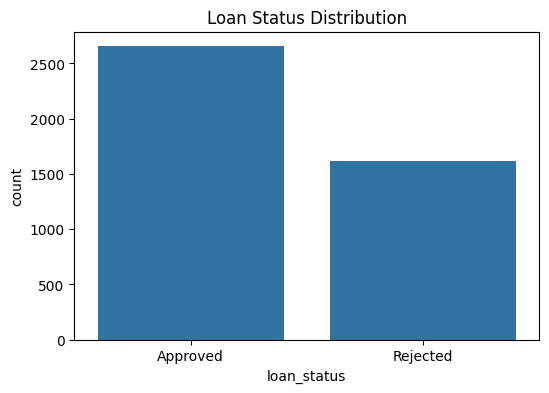

In [ ]:
# Target distribution
print("Target distribution:")
display(df["loan_status"].value_counts())

display(
    (df["loan_status"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="loan_status")
plt.title("Loan Status Distribution")
plt.xticks(rotation=0)
plt.show()


## 3) Feature Engineering

The engineered variables below are deterministic ratios/sums based only on the available predictor columns. They do not use `loan_status`.


In [ ]:
# Feature Engineering
df["total_assets"] = (
    df["residential_assets_value"]
    + df["commercial_assets_value"]
    + df["luxury_assets_value"]
    + df["bank_asset_value"]
)

df["non_bank_assets"] = (
    df["residential_assets_value"]
    + df["commercial_assets_value"]
    + df["luxury_assets_value"]
)

df["loan_income_ratio"] = (
    df["loan_amount"] / df["income_annum"].replace(0, np.nan)
)

df["loan_assets_ratio"] = (
    df["loan_amount"] / df["total_assets"].replace(0, np.nan)
)

df["assets_income_ratio"] = (
    df["total_assets"] / df["income_annum"].replace(0, np.nan)
)

df["loan_per_term"] = (
    df["loan_amount"] / df["loan_term"].replace(0, np.nan)
)

df["income_per_dependent"] = (
    df["income_annum"] / (df["no_of_dependents"] + 1)
)

df["assets_per_dependent"] = (
    df["total_assets"] / (df["no_of_dependents"] + 1)
)

df["bank_asset_ratio"] = (
    df["bank_asset_value"] / df["total_assets"].replace(0, np.nan)
)

# Convert inf produced by division into missing values
df = df.replace([np.inf, -np.inf], np.nan)

print("New shape:", df.shape)
display(df.head())


New shape: (4269, 21)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,total_assets,non_bank_assets,loan_income_ratio,loan_assets_ratio,assets_income_ratio,loan_per_term,income_per_dependent,assets_per_dependent,bank_asset_ratio
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved,50700000,42700000,3.114583,0.589744,5.281250,2.491667e+06,3.200000e+06,1.690000e+07,0.157791
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected,17000000,13700000,2.975610,0.717647,4.146341,1.525000e+06,4.100000e+06,1.700000e+07,0.194118
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected,57700000,44900000,3.263736,0.514731,6.340659,1.485000e+06,2.275000e+06,1.442500e+07,0.221837
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected,52700000,44800000,3.743902,0.582543,6.426829,3.837500e+06,2.050000e+06,1.317500e+07,0.149905
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected,55000000,50000000,2.469388,0.440000,5.612245,1.210000e+06,1.633333e+06,9.166667e+06,0.090909


In [ ]:
# Check the engineered features
engineered_cols = [
    "total_assets", "non_bank_assets", "loan_income_ratio",
    "loan_assets_ratio", "assets_income_ratio", "loan_per_term",
    "income_per_dependent", "assets_per_dependent", "bank_asset_ratio"
]

display(df[engineered_cols].describe().T)
print("Missing values created by feature engineering:")
display(df[engineered_cols].isna().sum().to_frame("missing"))


,count,mean,std,min,25%,50%,75%,max
total_assets,4269.0,3.254877e+07,1.950656e+07,400000.000000,1.630000e+07,3.150000e+07,4.720000e+07,9.070000e+07
non_bank_assets,4269.0,2.757208e+07,1.689176e+07,200000.000000,1.370000e+07,2.620000e+07,3.990000e+07,8.170000e+07
loan_income_ratio,4269.0,2.984807e+00,5.954957e-01,1.500000,2.464286e+00,3.000000e+00,3.500000e+00,4.000000e+00
loan_assets_ratio,4269.0,4.868568e-01,1.455541e-01,0.176471,3.822314e-01,4.666667e-01,5.658199e-01,1.333333e+00
assets_income_ratio,4269.0,6.390858e+00,1.251145e+00,2.000000,5.500000e+00,6.413043e+00,7.267857e+00,1.014286e+01
loan_per_term,4269.0,2.194899e+06,2.597537e+06,15000.000000,7.000000e+05,1.357143e+06,2.516667e+06,1.935000e+07
income_per_dependent,4269.0,2.055050e+06,2.003233e+06,33333.333333,7.750000e+05,1.450000e+06,2.500000e+06,9.900000e+06
assets_per_dependent,4269.0,1.322003e+07,1.342423e+07,100000.000000,4.750000e+06,9.133333e+06,1.625000e+07,8.330000e+07
bank_asset_ratio,4269.0,1.560482e-01,5.414107e-02,0.000000,1.150235e-01,1.517413e-01,1.904762e-01,5.000000e-01


Missing values created by feature engineering:


,missing
total_assets,0
non_bank_assets,0
loan_income_ratio,0
loan_assets_ratio,0
assets_income_ratio,0
loan_per_term,0
income_per_dependent,0
assets_per_dependent,0
bank_asset_ratio,0


## 4) Outlier Analysis

First, we report IQR outliers. We do **not** delete observations just because they are outliers: these are financial values, so extreme values can be valid applicants.

For modeling, we use **IQR capping (winsorization)** for the continuous financial variables. The lower/upper caps are learned from the training set only and then applied to both train and test. Bounded variables such as CIBIL score, dependents, and loan term are not capped merely because the IQR rule flags a value.


In [ ]:
# Outlier report on the full cleaned dataset (for EDA only)
outlier_rows = []

for col in df.select_dtypes(include=np.number).columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append([col, q1, q3, iqr, lower, upper, int(count)])

outlier_report = pd.DataFrame(
    outlier_rows,
    columns=["feature","Q1","Q3","IQR","lower_bound","upper_bound","outlier_count"]
).sort_values("outlier_count", ascending=False)

display(outlier_report)


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
14,loan_per_term,7.000000e+05,2.516667e+06,1.816667e+06,-2.025000e+06,5.241667e+06,406
16,assets_per_dependent,4.750000e+06,1.625000e+07,1.150000e+07,-1.250000e+07,3.350000e+07,355
15,income_per_dependent,7.750000e+05,2.500000e+06,1.725000e+06,-1.812500e+06,5.087500e+06,343
12,loan_assets_ratio,3.822314e-01,5.658199e-01,1.835885e-01,1.068487e-01,8.412025e-01,101
5,residential_assets_value,2.200000e+06,1.130000e+07,9.100000e+06,-1.145000e+07,2.495000e+07,52
17,bank_asset_ratio,1.150235e-01,1.904762e-01,7.545272e-02,1.844400e-03,3.036553e-01,43
6,commercial_assets_value,1.300000e+06,7.600000e+06,6.300000e+06,-8.150000e+06,1.705000e+07,37
8,bank_asset_value,2.300000e+06,7.100000e+06,4.800000e+06,-4.900000e+06,1.430000e+07,5
13,assets_income_ratio,5.500000e+00,7.267857e+00,1.767857e+00,2.848214e+00,9.919643e+00,5
10,non_bank_assets,1.370000e+07,3.990000e+07,2.620000e+07,-2.560000e+07,7.920000e+07,2


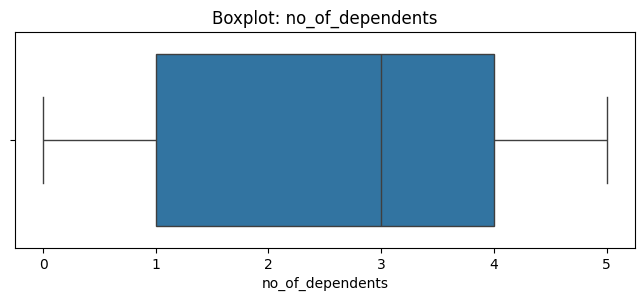

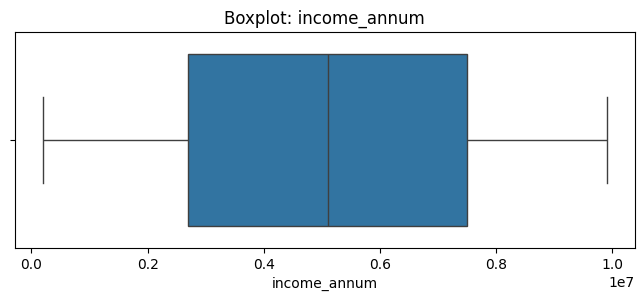

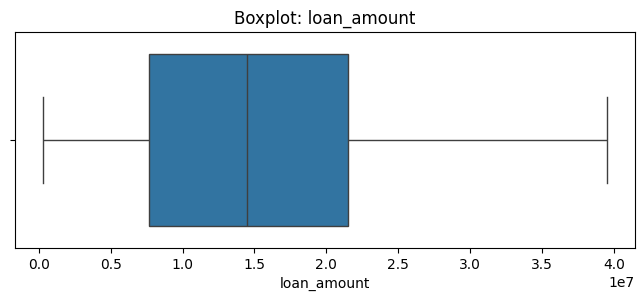

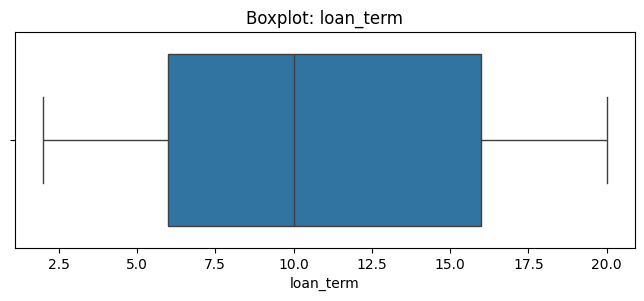

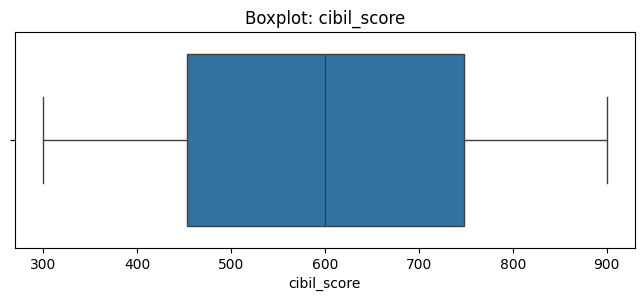

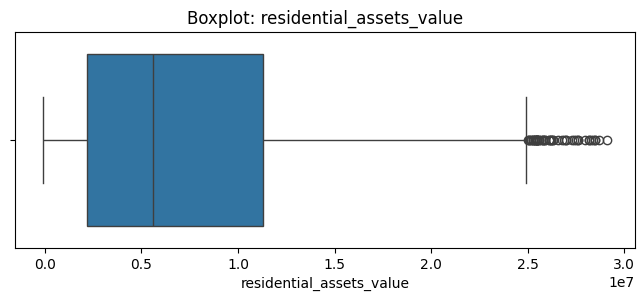

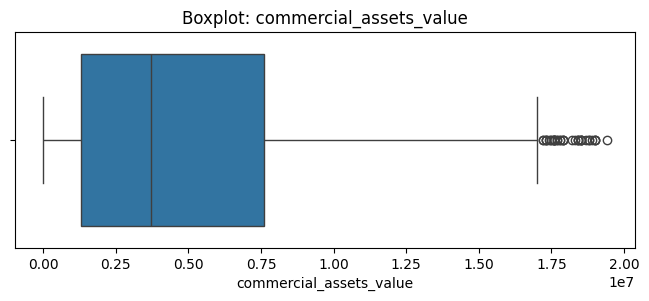

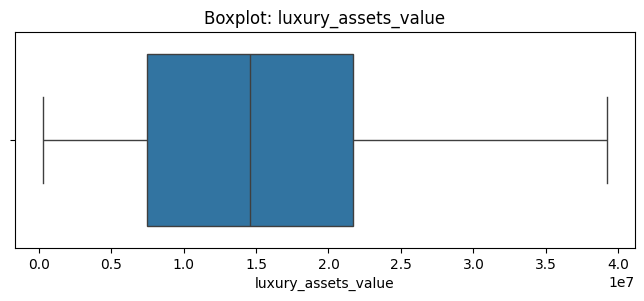

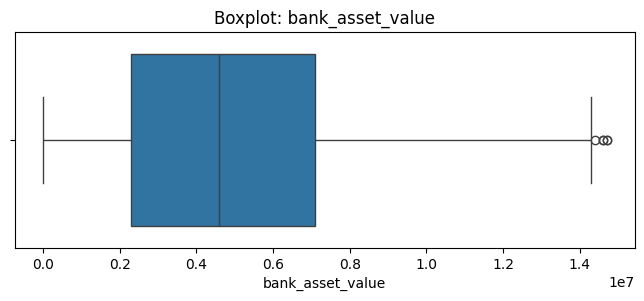

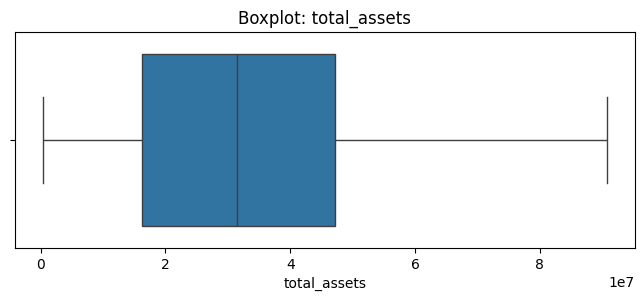

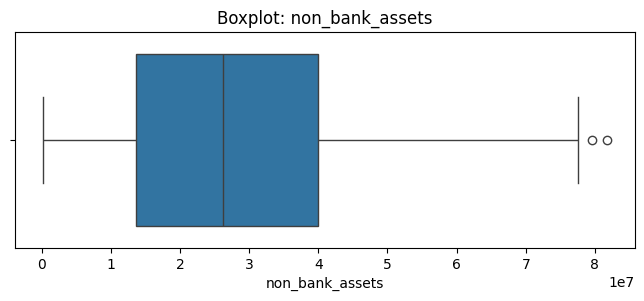

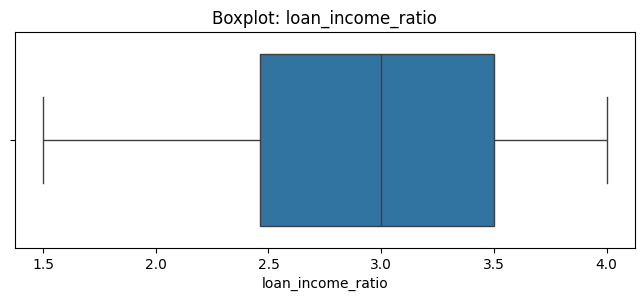

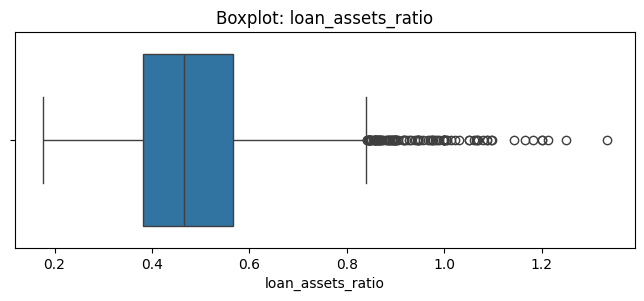

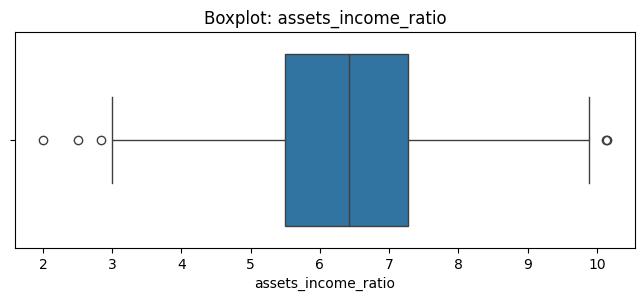

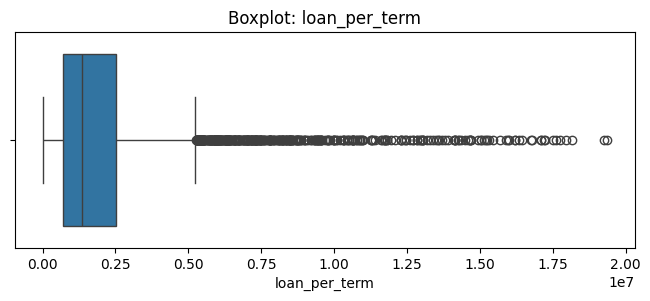

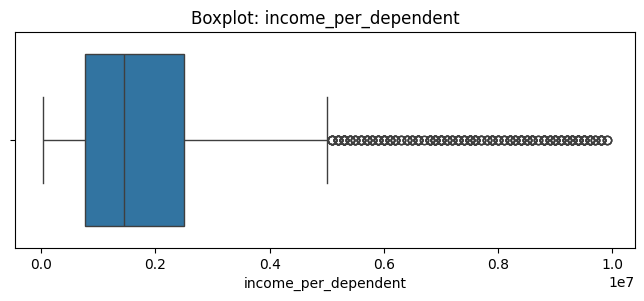

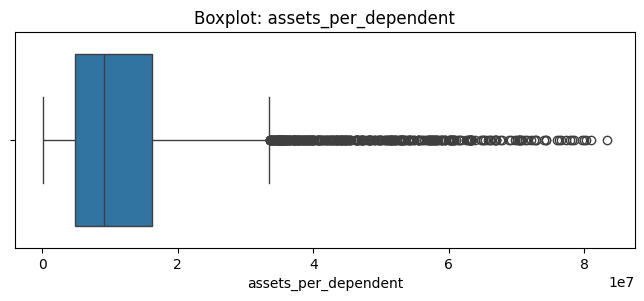

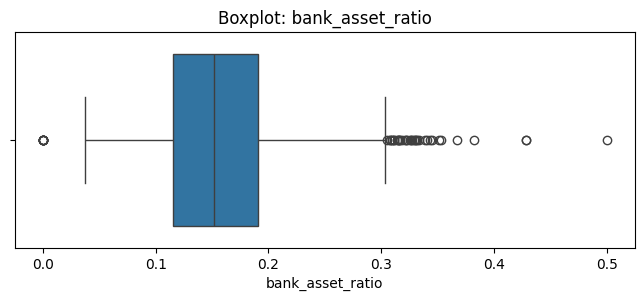

In [ ]:
# Boxplots for numerical variables
for col in df.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(8, 2.8))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")
    plt.show()


In [ ]:
# Encode target
df["loan_status"] = df["loan_status"].map({
    "Approved": 1,
    "Rejected": 0
})

# Encode categorical columns
df = pd.get_dummies(
    df,
    columns=["education", "self_employed"],
    drop_first=True,
    dtype=int
)

# Remove missing values
df = df.dropna()

# Show columns
print(df.columns)

Index(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status',
       'total_assets', 'non_bank_assets', 'loan_income_ratio',
       'loan_assets_ratio', 'assets_income_ratio', 'loan_per_term',
       'income_per_dependent', 'assets_per_dependent', 'bank_asset_ratio',
       'education_Not Graduate', 'self_employed_Yes'],
      dtype='object')


## 5) Train/Test Split and Outlier Capping

The split is done **before fitting** outlier thresholds and the scaler. This is important: if test-set statistics are used to calculate caps or scaling parameters, the evaluation becomes optimistic.

The test set is still transformed using the training-set rules.


In [ ]:
# Separate features and target
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Show the sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (2988, 20)
Testing data: (1281, 20)


In [ ]:
# Columns to handle outliers
features = [
    "income_annum", "loan_amount",
    "residential_assets_value", "commercial_assets_value",
    "luxury_assets_value", "bank_asset_value",
    "total_assets", "non_bank_assets",
    "loan_income_ratio", "loan_assets_ratio",
    "assets_income_ratio", "loan_per_term",
    "income_per_dependent", "assets_per_dependent",
    "bank_asset_ratio"
]

# Calculate limits from training data
limits = {}

for col in features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    limits[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

# Apply capping
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

for col in features:
    X_train_capped[col] = X_train_capped[col].clip(*limits[col])
    X_test_capped[col] = X_test_capped[col].clip(*limits[col])

print("Outliers handled successfully")

Outliers handled successfully


In [ ]:
# Count capped values
for col in features:
    lower, upper = limits[col]

    train_count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    test_count = ((X_test[col] < lower) | (X_test[col] > upper)).sum()

    print(col, "Train:", train_count, "Test:", test_count)


income_annum Train: 0 Test: 0
loan_amount Train: 0 Test: 0
residential_assets_value Train: 44 Test: 15
commercial_assets_value Train: 28 Test: 4
luxury_assets_value Train: 0 Test: 0
bank_asset_value Train: 4 Test: 4
total_assets Train: 0 Test: 0
non_bank_assets Train: 2 Test: 0
loan_income_ratio Train: 0 Test: 0
loan_assets_ratio Train: 74 Test: 27
assets_income_ratio Train: 6 Test: 0
loan_per_term Train: 302 Test: 108
income_per_dependent Train: 238 Test: 105
assets_per_dependent Train: 251 Test: 115
bank_asset_ratio Train: 31 Test: 11


## 6) Scaling

`StandardScaler` is used for Logistic Regression. Decision Tree and Random Forest do not require scaling, so they use the capped numerical features directly.

The scaler is fitted only on `X_train_capped`.


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_capped)
X_test_scaled = scaler.transform(X_test_capped)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape :", X_test_scaled.shape)


Scaled train shape: (2988, 20)
Scaled test shape : (1281, 20)


## 7) Evaluation


In [ ]:
results = []

def evaluate_model(name, model, X_train, X_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Train F1": f1_score(y_train, train_pred),

        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Test F1": f1_score(y_test, test_pred)
    })

## 8) Logistic Regression — Normal, Ridge, Lasso

- Normal Logistic Regression: very weak L2 regularization (`C` very large) to approximate the unregularized model.
- Ridge: L2 regularization.
- Lasso: L1 regularization.


In [ ]:
# Normal Logistic Regression
log_normal = LogisticRegression(C=1e6, solver="liblinear", max_iter=2000)
log_normal.fit(X_train_scaled, y_train)
evaluate_model("Normal", log_normal, X_train_scaled, X_test_scaled)

# Ridge (L2)
log_ridge = LogisticRegression(C=1.0, penalty="l2", solver="liblinear", max_iter=2000)
log_ridge.fit(X_train_scaled, y_train)
evaluate_model("Ridge", log_ridge, X_train_scaled, X_test_scaled)

# Lasso (L1)
log_lasso = LogisticRegression(C=1.0, penalty="l1", solver="liblinear", max_iter=2000)
log_lasso.fit(X_train_scaled, y_train)
evaluate_model("Lasso", log_lasso, X_train_scaled, X_test_scaled)
pd.DataFrame(results)


,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Normal,0.923360,0.937232,0.939753,0.938490,0.927400,0.938903,0.944793,0.941839
1,Ridge,0.921687,0.936593,0.937601,0.937097,0.925839,0.938750,0.942284,0.940513
2,Lasso,0.920348,0.935051,0.937063,0.936056,0.924278,0.938596,0.939774,0.939185


## 9) Decision Tree — Before Grid Search


In [ ]:
dt_before = DecisionTreeClassifier(random_state=42)
dt_before.fit(X_train_capped, y_train)

evaluate_model(
    "Decision Tree (Before Grid)",
    dt_before,
    X_train_capped,
    X_test_capped
)

print("Tree depth:", dt_before.get_depth())
print("Number of leaves:", dt_before.get_n_leaves())


Tree depth: 5
Number of leaves: 10


## 10) Decision Tree — Grid Search


In [ ]:
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

dt_grid.fit(X_train_capped, y_train)

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)
print("Best CV accuracy:", round(dt_grid.best_score_, 4))

evaluate_model(
    "Decision Tree (After Grid)",
    dt_grid.best_estimator_,
    X_train_capped,
    X_test_capped
)


Best Decision Tree parameters:
{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.998


## 11) Random Forest — Before Grid Search


In [ ]:
rf_before = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_before.fit(X_train_capped, y_train)

evaluate_model(
    "Random Forest (Before Grid)",
    rf_before,
    X_train_capped,
    X_test_capped
)


## 12) Random Forest — Grid Search


In [ ]:
# A focused grid: enough to tune the model without creating thousands of fits.
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train_capped, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best CV accuracy:", round(rf_grid.best_score_, 4))

evaluate_model(
    "Random Forest (After Grid)",
    rf_grid.best_estimator_,
    X_train_capped,
    X_test_capped
)


Best Random Forest parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}
Best CV accuracy: 0.9953


## 13) Final Comparison Table — All Models


In [ ]:
results_df = pd.DataFrame(results)

# Put the models in the requested order
model_order = [
    "Logistic Regression (Normal)",
    "Logistic Regression (Ridge / L2)",
    "Logistic Regression (Lasso / L1)",
    "Decision Tree (Before Grid)",
    "Decision Tree (After Grid)",
    "Random Forest (Before Grid)",
    "Random Forest (After Grid)"
]

results_df["Model"] = pd.Categorical(
    results_df["Model"],
    categories=model_order,
    ordered=True
)

results_df = results_df.sort_values("Model").reset_index(drop=True)

display(results_df.round(4))


,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Decision Tree (Before Grid),1.0000,1.0000,1.0000,1.0000,0.9984,0.9987,0.9987,0.9987
1,Decision Tree (After Grid),0.9987,0.9979,1.0000,0.9989,0.9977,0.9962,1.0000,0.9981
2,Random Forest (Before Grid),1.0000,1.0000,1.0000,1.0000,0.9977,0.9962,1.0000,0.9981
3,Random Forest (After Grid),0.9970,0.9952,1.0000,0.9976,0.9977,0.9962,1.0000,0.9981
4,NaN,0.9234,0.9372,0.9398,0.9385,0.9274,0.9389,0.9448,0.9418
5,NaN,0.9217,0.9366,0.9376,0.9371,0.9258,0.9388,0.9423,0.9405
6,NaN,0.9203,0.9351,0.9371,0.9361,0.9243,0.9386,0.9398,0.9392


## 14) Test-Set Comparison Only

This table makes it easy to compare the models on unseen test data.


In [ ]:
test_comparison = results_df[
    ["Model", "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
].copy()

display(test_comparison.round(4))


,Model,Test Accuracy,Test Precision,Test Recall,Test F1
0,Decision Tree (Before Grid),0.9984,0.9987,0.9987,0.9987
1,Decision Tree (After Grid),0.9977,0.9962,1.0000,0.9981
2,Random Forest (Before Grid),0.9977,0.9962,1.0000,0.9981
3,Random Forest (After Grid),0.9977,0.9962,1.0000,0.9981
4,NaN,0.9274,0.9389,0.9448,0.9418
5,NaN,0.9258,0.9388,0.9423,0.9405
6,NaN,0.9243,0.9386,0.9398,0.9392


## 15) Confusion Matrices and Classification Reports

The final tuned Decision Tree and Random Forest are evaluated on the held-out test set.


Decision Tree (After Grid)
              precision    recall  f1-score   support

    Rejected       1.00      0.99      1.00       484
    Approved       1.00      1.00      1.00       797

    accuracy                           1.00      1281
   macro avg       1.00      1.00      1.00      1281
weighted avg       1.00      1.00      1.00      1281



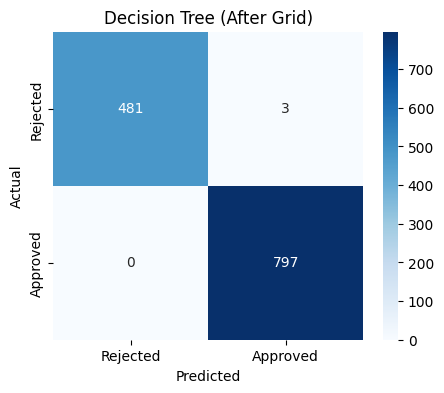

Random Forest (After Grid)
              precision    recall  f1-score   support

    Rejected       1.00      0.99      1.00       484
    Approved       1.00      1.00      1.00       797

    accuracy                           1.00      1281
   macro avg       1.00      1.00      1.00      1281
weighted avg       1.00      1.00      1.00      1281



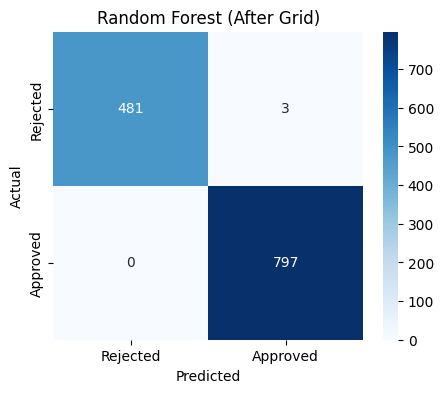

In [ ]:
final_models = {
    "Decision Tree (After Grid)": dt_grid.best_estimator_,
    "Random Forest (After Grid)": rf_grid.best_estimator_
}

for name, model in final_models.items():
    pred = model.predict(X_test_capped)

    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        pred,
        target_names=["Rejected", "Approved"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Rejected", "Approved"],
        yticklabels=["Rejected", "Approved"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(name)
    plt.show()


## 17) Final Checklist

### Removed
- `loan_id` because it is only an identifier.

### Checked
- Missing values
- Duplicate rows
- Data types
- Categorical values
- Negative values
- Constant columns
- Target distribution
- IQR outliers
- Engineered-feature validity

### Feature Engineering
- `total_assets`
- `non_bank_assets`
- `loan_income_ratio`
- `loan_assets_ratio`
- `assets_income_ratio`
- `loan_per_term`
- `income_per_dependent`
- `assets_per_dependent`
- `bank_asset_ratio`

### Outliers
- Financial continuous variables are IQR-capped using **training-set thresholds**.
- Domain-bounded variables such as CIBIL score, loan term, and number of dependents are not arbitrarily deleted/capped.

### Encoding
- `loan_status`: Approved = 1, Rejected = 0
- `education` and `self_employed`: one-hot/binary encoded.

### Scaling
- StandardScaler for Logistic Regression.
- Tree models use capped but unscaled features.

### Models
- Logistic Regression: Normal, Ridge/L2, Lasso/L1
- Decision Tree: Before and After Grid Search
- Random Forest: Before and After Grid Search

### Final output
The final `results_df` is the requested comparison table containing Train/Test Accuracy, Precision, Recall, and F1 for every model.
